# Escaped Asteroid Analysis
The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm


In [2]:

pa_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mvc_3/inputs/clone_assignments.h5')
ea_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mvc_3/escaped_asteroids.h5')


In [3]:
print(pa_mvc3.sort_values(['sim_no', 'particle_number']).tail())

         ast_name                     particle_types  sim_no  particle_number
38088  2000 RV111  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043               11
57133       P_426  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043               12
19044      488807              [X, Y, Z, VX, VY, VZ]   19044               10
38089  2000 RV111              [X, Y, Z, VX, VY, VZ]   19044               11
57134       P_426              [X, Y, Z, VX, VY, VZ]   19044               12


In [4]:
ea_mvc3.describe()

,particle_number,parameter,parameter_value,integration_year
count,318.000000,318.000000,318.000000,3.180000e+02
mean,11.267296,6.660377,3.301352,1.530877e+09
std,0.818323,0.722161,6.208681,1.561553e+09
min,10.000000,6.000000,0.000000,7.478726e+07
25%,11.000000,6.000000,0.346048,3.302239e+08
50%,12.000000,7.000000,0.431197,9.928510e+08
75%,12.000000,7.000000,4.571803,2.124721e+09
max,12.000000,8.000000,43.255570,6.154367e+09


In [5]:
print(f"Venus Ceres Mercurious escaped asteroids:{(ea_mvc3['ast_name']+ea_mvc3['vectors']).nunique()}")


Venus Ceres Mercurious escaped asteroids:162


In [6]:
ea_mvc3.sort_values(by=['ast_name', 'vectors']).head(20)

,ast_name,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
43,1303,XcpYcpZcmVXcpVYcmVZcp,00010,10,6,4.051143,5.234418e+09
45,1303,XcpYcpZcmVXcpVYcmVZcp,00010,10,7,0.599913,5.221851e+09
46,1303,XcpYcpZcmVXcpVYcmVZcp,00010,10,8,0.590840,5.224993e+09
235,16794,XcmYcmZcmVXcmVYcpVZcm,00191,10,6,4.036795,2.203112e+09
238,16794,XcmYcmZcmVXcmVYcpVZcm,00191,10,7,0.399399,2.133361e+09
240,16794,XcmYcmZcmVXcmVYcpVZcm,00191,10,8,0.743397,2.203112e+09
23,16794,XcmYcmZcpVXcmVYcpVZcm,00183,10,6,4.790435,2.678167e+09
26,16794,XcmYcmZcpVXcmVYcpVZcm,00183,10,7,0.447256,2.657431e+09
28,16794,XcmYcmZcpVXcmVYcpVZcm,00183,10,8,0.602651,2.656802e+09
259,16794,XcmYcmZcpVXcpVYcmVZcm,00181,10,6,1.153088,1.658934e+09


In [7]:
print(ea_mvc3.groupby(['parameter']).max())
print(ea_mvc3.groupby(['parameter']).min())

          ast_name                vectors sim_no  particle_number   
parameter                                                           
6           507863  XcpYcpZcpVXcpVYcpVZcp  00563               12  \
7           507863  XcpYcpZcpVXcpVYcpVZcp  00563               12   
8           507863  XcpYcpZcpVXcpVYcpVZcp  00563               12   

           parameter_value  integration_year  
parameter                                     
6                43.255570      6.154367e+09  
7                 0.665960      6.150597e+09  
8                 1.518082      6.151854e+09  
          ast_name    vectors sim_no  particle_number  parameter_value   
parameter                                                                
6             1303  XYZVXVYVZ  00010               10         0.000000  \
7             1303  XYZVXVYVZ  00010               10         0.340155   
8             1303  XYZVXVYVZ  00010               10         0.555238   

           integration_year  
parameter         

In [8]:
ea_mvc3.groupby(['ast_name']).count()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
1303,3,3,3,3,3,3
16794,72,72,72,72,72,72
2001 QO310,5,5,5,5,5,5
2002 FL44,135,135,135,135,135,135
2003 FY123,20,20,20,20,20,20
493333,8,8,8,8,8,8
499395,32,32,32,32,32,32
507863,43,43,43,43,43,43


In [9]:
escapee_years = ea_mvc3.loc[ea_mvc3.parameter == 6][['ast_name', 'vectors', 'integration_year']]
escapee_years.sort_values(by=['integration_year'])


,ast_name,vectors,integration_year
98,2003 FY123,XcmYcpZcpVXcmVYcmVZcm,1.137468e+08
53,2002 FL44,XcpYcpZcpVXcmVYcpVZcm,1.238009e+08
230,2002 FL44,XcmYcmZcpVXcmVYcmVZcm,1.344834e+08
121,2002 FL44,XcmYcpZcmVXcpVYcpVZcm,1.432807e+08
269,2002 FL44,XcmYcpZcpVXcpVYcpVZcm,1.439091e+08
...,...,...,...
128,507863,XcmYcpZcmVXcpVYcmVZcp,5.407851e+09
97,507863,XcmYcpZcpVXcmVYcmVZcm,5.524102e+09
192,507863,XcmYcpZcmVXcpVYcpVZcm,6.035603e+09
296,16794,XcpYcmZcpVXcmVYcmVZcm,6.153111e+09


(array([69., 18., 24.,  9.,  9.,  3.,  4.,  8.,  8.,  3.]),
 array([1.81033729e+07, 1.14242834e+08, 2.10382295e+08, 3.06521756e+08,
        4.02661217e+08, 4.98800678e+08, 5.94940139e+08, 6.91079600e+08,
        7.87219061e+08, 8.83358521e+08, 9.79497982e+08]),
 <BarContainer object of 10 artists>)

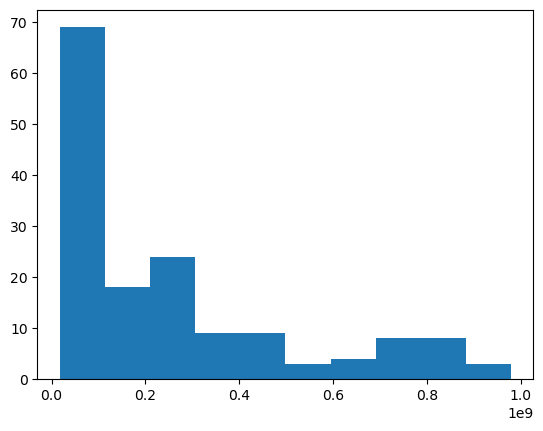

In [10]:
plt.hist(escapee_years.integration_year/(2*np.pi))

In [11]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])
mag_h = 17
p_v = 0.0387
luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.head())

  ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
0     1303     9.48  3.219248  0.121842  0.322276      1303  0.328133  \
1    11911    11.80  3.210027  0.132169  0.330567      1303  0.336904   
2    16794    13.45  3.229767  0.120773  0.321221      1303  0.327019   
3    17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
4    26558    13.15  3.194646  0.115763  0.319342      1303  0.325035   

        ideg       diam  
0  18.800624  85.836005  
1  19.303194  29.489642  
2  18.736782  13.793342  
3  18.836035  21.760531  
4  18.623137  15.836875  


In [12]:
luth_fam.set_index('ast_name')

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005
11911,11.80,3.210027,0.132169,0.330567,1303,0.336904,19.303194,29.489642
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
26558,13.15,3.194646,0.115763,0.319342,1303,0.325035,18.623137,15.836875
...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842


In [13]:
escaped_asts = ea_mvc3.ast_name.unique()
escaped_asts = [x.replace(' ','') for x in escaped_asts]
escaped_asts

['2002FL44',
 '16794',
 '499395',
 '2001QO310',
 '493333',
 '507863',
 '2003FY123',
 '1303']

In [14]:
luth_fam[luth_fam.ast_name.isin(escaped_asts)==True]

,ast_name,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
0,1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005
2,16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
293,493333,15.71,3.227294,0.122424,0.323283,1303,0.329197,18.861583,4.871576
295,499395,16.54,3.216326,0.134521,0.330983,1303,0.337345,19.328450,3.324065
301,507863,16.17,3.235970,0.114281,0.322138,1303,0.327987,18.792271,3.941572
586,2001QO310,16.80,3.191888,0.113097,0.315359,1303,0.320835,18.382488,2.948964
588,2002FL44,16.38,3.212787,0.135076,0.330553,1303,0.336889,19.302344,3.578240
594,2003FY123,16.90,3.207697,0.125826,0.325764,1303,0.331820,19.011868,2.816239


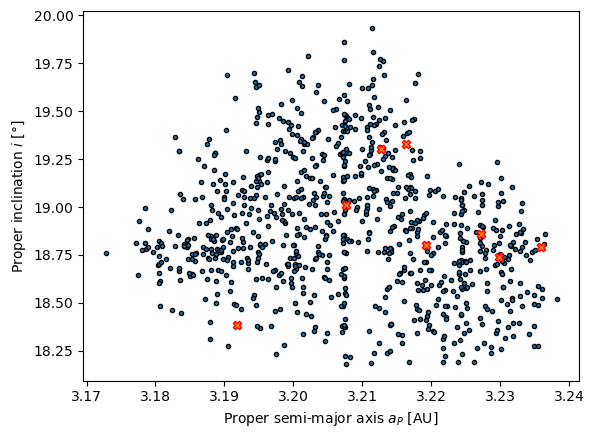

In [15]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='ideg', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='ideg', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper inclination $i$ [$\degree$]")
plt.show()

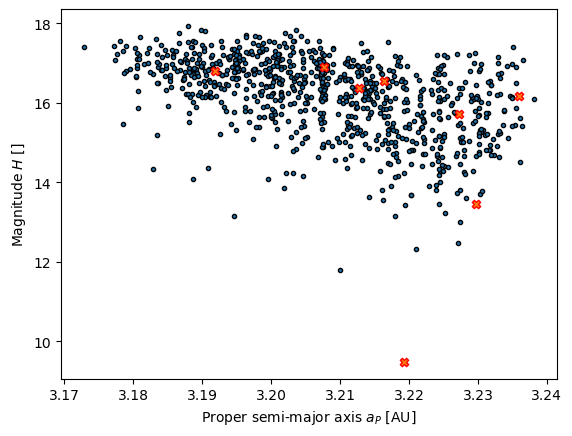

In [16]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='abs_mag', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='abs_mag', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude $H$ []")
plt.show()

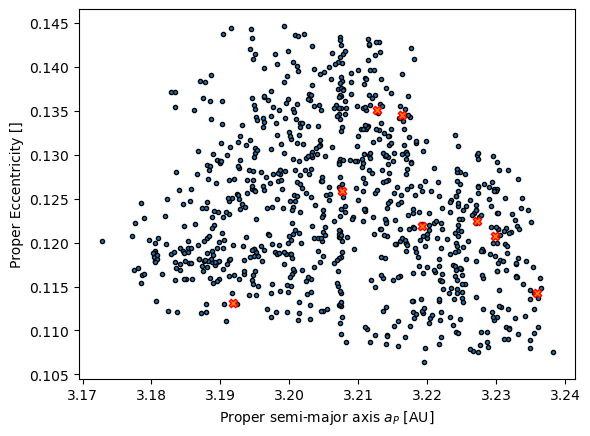

In [17]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='e_P', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='e_P', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

In [18]:
test_fam = luth_fam.copy()
test_fam = test_fam.set_index('ast_name')

In [19]:
mean_escape = escapee_years.groupby('ast_name').mean('integration_year')
mean_escape.index = [x.replace(' ','') for x in mean_escape.index]
mean_escape

,integration_year
1303,5.234418e+09
16794,2.600412e+09
2001QO310,4.097804e+09
2002FL44,6.883804e+08
2003FY123,6.005453e+08
493333,3.390332e+09
499395,2.657062e+09
507863,1.778955e+09


In [20]:
test_fam['integration_year'] = mean_escape
test_fam = test_fam.fillna(value={'integration_year': 0})
test_fam['graph_symbol'] = '.'
test_fam.loc[test_fam['integration_year']!=0,['graph_symbol']] = 'X'
test_fam

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam,integration_year,graph_symbol
ast_name,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005,5.234418e+09,X
11911,11.80,3.210027,0.132169,0.330567,1303,0.336904,19.303194,29.489642,0.000000e+00,.
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342,2.600412e+09,X
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531,0.000000e+00,.
26558,13.15,3.194646,0.115763,0.319342,1303,0.325035,18.623137,15.836875,0.000000e+00,.
...,...,...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964,0.000000e+00,.
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399,0.000000e+00,.
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842,0.000000e+00,.


ast_name
1303         0.833084
16794        0.413868
493333       0.539588
499395       0.422885
507863       0.283129
2001QO310    0.652186
2002FL44     0.109559
2003FY123    0.095580
Name: integration_year, dtype: float64


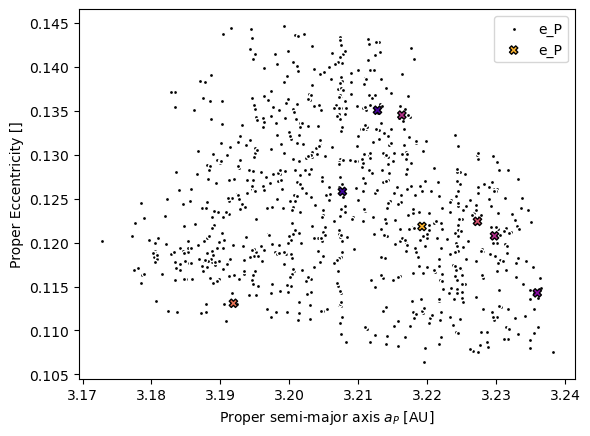

In [21]:
for graph_symbol, m_fam in test_fam.groupby('graph_symbol'):
    if graph_symbol == '.':
        plt.scatter(data=m_fam, x='a_P',y='e_P', edgecolors='white', marker=graph_symbol, 
        c='black')
    else:
        colour_values = (m_fam['integration_year']/(2*np.pi))/1.0e9
        edge = 'black'
        plt.scatter(data=m_fam, x='a_P',y='e_P', edgecolors=edge, marker=graph_symbol, 
                c=cm.plasma(colour_values))
        print(colour_values)
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.legend()
plt.show()

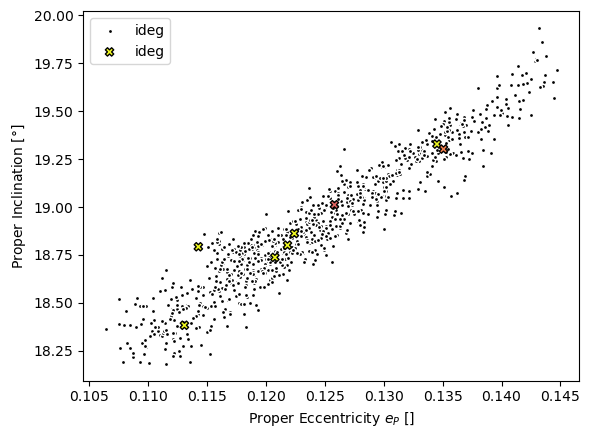

In [26]:
for graph_symbol, m_fam in test_fam.groupby('graph_symbol'):
    if graph_symbol == '.':
        plt.scatter(data=m_fam, x='e_P',y='ideg', edgecolors='white', marker=graph_symbol, 
        c='black')

    else:
        edge = 'black'
        plt.scatter(data=m_fam, x='e_P',y='ideg', edgecolors=edge, marker=graph_symbol, 
                c=cm.plasma(m_fam['integration_year']/1.0e9))
    
plt.xlabel("Proper Eccentricity $e_P$ []")
plt.ylabel("Proper Inclination [$\degree$]")
plt.legend()
plt.show()

In [23]:
periods = [1,2,3]
sm_axes = []

jupiter_a = 5.204
jupiter_p = jupiter_a**(3/2)

print(f'jupiter period:{jupiter_p}')

kirkwood_a = 3.5
kirwood_p = kirkwood_a**(3/2)

print(f'kirkwood_mmr period:{kirwood_p}')

print(f'3:1 period AU:{(jupiter_p*(1/3))**(2/3)}')
print(f'5:2 period AU:{(jupiter_p*(2/5))**(2/3)}')
print(f'7:3 period AU:{(jupiter_p*(3/7))**(2/3)}')
print(f'9:4 period AU:{(jupiter_p*(4/9))**(2/3)}')
print(f'2:1 period AU:{(jupiter_p*(1/2))**(2/3)}')
print(f'11:6 period AU:{(jupiter_p*(6/11))**(2/3)}')

mars_a = 1.524
mars_p = mars_a**(3/2)
print(f'Mars 1:3 period AU:{(mars_p*(3/1))**(2/3)}')



jupiter period:11.871509156969049
kirkwood_mmr period:6.547900426854397
3:1 period AU:2.501822254626584
5:2 period AU:2.8251658553519783
7:3 period AU:2.9581448156989745
9:4 period AU:3.0307418256584655
2:1 period AU:3.2783145718264595
11:6 period AU:3.474105462228
Mars 1:3 period AU:3.1700477463311016


In [24]:
gap_a_au = 3.209

print(f'Gap AU:{(jupiter_p*(12/25))**(2/3)}')

gap_p_yr = gap_a_au**(2/3)
print(f"Period for gap at {gap_a_au} is {gap_p_yr}")

jupiter_orbits = np.arange(1,10)
aster_orbits = np.arange(2,20)

possible_ratios = jupiter_orbits[:,np.newaxis]/aster_orbits  
np.set_printoptions(precision=2)
print(possible_ratios)


Gap AU:3.19029942894084
Period for gap at 3.209 is 2.1756038135077427
[[0.5  0.33 0.25 0.2  0.17 0.14 0.12 0.11 0.1  0.09 0.08 0.08 0.07 0.07
  0.06 0.06 0.06 0.05]
 [1.   0.67 0.5  0.4  0.33 0.29 0.25 0.22 0.2  0.18 0.17 0.15 0.14 0.13
  0.12 0.12 0.11 0.11]
 [1.5  1.   0.75 0.6  0.5  0.43 0.38 0.33 0.3  0.27 0.25 0.23 0.21 0.2
  0.19 0.18 0.17 0.16]
 [2.   1.33 1.   0.8  0.67 0.57 0.5  0.44 0.4  0.36 0.33 0.31 0.29 0.27
  0.25 0.24 0.22 0.21]
 [2.5  1.67 1.25 1.   0.83 0.71 0.62 0.56 0.5  0.45 0.42 0.38 0.36 0.33
  0.31 0.29 0.28 0.26]
 [3.   2.   1.5  1.2  1.   0.86 0.75 0.67 0.6  0.55 0.5  0.46 0.43 0.4
  0.38 0.35 0.33 0.32]
 [3.5  2.33 1.75 1.4  1.17 1.   0.88 0.78 0.7  0.64 0.58 0.54 0.5  0.47
  0.44 0.41 0.39 0.37]
 [4.   2.67 2.   1.6  1.33 1.14 1.   0.89 0.8  0.73 0.67 0.62 0.57 0.53
  0.5  0.47 0.44 0.42]
 [4.5  3.   2.25 1.8  1.5  1.29 1.12 1.   0.9  0.82 0.75 0.69 0.64 0.6
  0.56 0.53 0.5  0.47]]


In [79]:
from math import floor, pow, log10
int_length = 1.0e9
exp = floor(log10(int_length))

log_time = int(int_length / pow(10, exp-4))

print(f"Int time {int_length}, Calculated log time {log_time}")

one_mill = np.linspace(log_time, int_length*2*np.pi, log_time)
one_diff = one_mill[2]-one_mill[1]
print(f"Years between log records {one_diff/(2*np.pi)}")
print(f"Last one mill {one_mill[-1]}, length first {len(one_mill)}")
print(one_mill[1:]-one_mill[:-1])

two_lp = np.linspace(one_mill[-1]+one_diff, 2.5e9*2*np.pi, log_time)
print(f"2 linspace array first value {two_lp[0]}, Number of records{len(two_lp)}, End year {two_lp[-1]/(2*np.pi)}")
print(f"2Array first val {two_lp[0]}, diff between 1&2 array {(two_lp[0]-one_mill[-1])/(2*np.pi)}")
print(f"len2a {len(two_lp)}, final year {two_lp[-1]/(2*np.pi)}")
print(two_lp[1:]-two_lp[:-1])

two_mill = np.arange(one_mill[-1]+one_diff, 2.5e9*2*np.pi, one_diff)
print(f"first arange {two_mill[0]}, diff between 1&2 array {(two_mill[0]-one_mill[-1])/(2*np.pi)}, array len {len(two_mill)}, last year {two_mill[-1]/(2*np.pi)}")
print(two_mill[1:]-two_mill[:-1])


Int time 1000000000.0, Calculated log time 10000
Years between log records 100009.84182923984
Last one mill 6283185307.179586, length first 10000
[628380.37 628380.37 628380.37 ... 628380.37 628380.37 628380.37]
2 linspace array first value 6283813687.548341, Number of records10000, End year 2500000000.0
2Array first val 6283813687.548341, diff between 1&2 array 100009.84182916865
len2a 10000, final year 2500000000.0
[942509.21 942509.21 942509.21 ... 942509.21 942509.21 942509.21]
firs arange 6283813687.548341, diff between 1&2 array 100009.84182916865, array len 14998, last year 2499947607.7538714
[628380.37 628380.37 628380.37 ... 628380.37 628380.37 628380.37]


In [80]:
test = np.concatenate([one_mill, two_mill], axis=0)

In [104]:
np.unique(np.around(test[1:]-test[:-1],decimals=6))
print(one_mill[-1], two_mill[0], two_mill[0]-one_mill[-1])
print(test[len(one_mill)-1] - one_mill[-1], test[len(one_mill)]-two_mill[0])

6283185307.179586 6283813687.548341 628380.3687543869
0.0 0.0
